In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_u_2D, plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together
from PwpHex_class import PiecewiseLinearPolynomialsHex
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from minmax_opt_class_mgnn import MinMaxOptProb

In [2]:
def u0(x):
    return -jnp.sin(jnp.pi*x)

# Boundary at x=-1
def u1(x):
    return 0
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

t_min = 0
t_max = 1
x_min = -1
x_max = 1

In [3]:
import jax.numpy as jnp
from jax import vmap
import numpy as np

# The PiecewiseLinearPolynomials class definition here (copy from previous messages)

def test_quadrature():
    # Parameters for the domain [0, 0.5] x [-1, 1] x [0, 2]
    N_t = 10  # Divisions in t
    N_x = 5  # Divisions in x
    N_y = 2  # Divisions in y
    t_min = 0.0
    t_max = 1.5
    x_min = -1.0
    x_max = 1.0
    y_min = 0.0
    y_max = 2.0
    gauss_order = 5  # For accurate quadrature

    # Instantiate the class
    pwp = PiecewiseLinearPolynomialsHex(
        N_t=N_t, N_x=N_x, N_y=N_y,
        t_min=t_min, t_max=t_max,
        x_min=x_min, x_max=x_max,
        y_min=y_min, y_max=y_max,
        gauss_order=gauss_order
    )

    # Define the function f(t, x, y) = sin(t) * x^2 + sin(t) * y^3
    def f(txy):
        t, x, y = txy
        return jnp.sin(t) * x**2 + jnp.sin(t) * y**3

    # Vectorized function evaluation
    f_vec = vmap(f)(pwp.quad_points)
    # Numerical integral = sum(f * weights)
    numerical_integral = jnp.sum(f_vec * pwp.quad_weights)

    # Analytical integral
    # ∫_0^t_max sin(t) dt = 1 - cos(t_max)
    int_sin_t = 1 - jnp.cos(t_max)
    # ∫_{-1}^1 ∫_0^2 x^2 dy dx = 2 * ∫_{-1}^1 x^2 dx = 2 * (2/3) = 4/3
    int_x2 = 4 / 3
    # ∫_{-1}^1 ∫_0^2 y^3 dy dx = ∫_{-1}^1 4 dx = 8
    int_y3 = 8
    analytical_integral = int_sin_t * (int_x2 + int_y3)

    print("Numerical Integral:", numerical_integral)
    print("Analytical Integral:", analytical_integral)
    print("Absolute Error:", jnp.abs(numerical_integral - analytical_integral))

# Run the test
test_quadrature()

Numerical Integral: 8.673119
Analytical Integral: 8.67312
Absolute Error: 9.536743e-07


In [14]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1.5
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0
gauss_order = 3  # For accurate quadrature

# Instantiate the class
pwp = PiecewiseLinearPolynomialsHex(
    N_t=N_t, N_x=N_x, N_y=N_y,
    t_min=t_min, t_max=t_max,
    x_min=x_min, x_max=x_max,
    y_min=y_min, y_max=y_max,
    gauss_order=gauss_order
)
parti_idx = 0
quad_points = pwp.quad_points_parti[parti_idx]
quad_weights = pwp.quad_weights_parti[parti_idx]
print(pwp.quad_weights_parti.shape)

(100, 27)


In [20]:
import numpy as np
import jax.numpy as jnp

x_np = np.arange(10)
x_jnp = jnp.arange(10)

### NumPy
try: # prints: You cannot do this in NumPy
    print(x_np[13]) # indexing single index
except IndexError:
    print("You cannot do this in NumPy")
try: # prints: []
    print(x_np[13:15]) # indexing range of indices
except IndexError:
    print("You cannot do this in NumPy")

# JAX
try: # prints: 9
    print(x_jnp[13]) # indexing single index
except IndexError:
    print("You cannot do this in JAX")
try: # prints: []
    print(x_jnp[13:15]) # indexing range of indices
except IndexError:
    print("You cannot do this in JAX")

You cannot do this in NumPy
[]
9
[]


In [2]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1

import numpy as np

def u_ref(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = x <= 0.5 - 3*t/5
    cond2 = (0.5 - 3*t/5 < x) & (x <= 0.5 - t/4)
    cond3 = (0.5 - t/4 < x) & (x <= 0.5 + t/2)
    cond4 = (0.5 + t/2 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 + 3*t[cond1]/20, -0.2, 0.5)

    # Case 2
    u[cond2] = np.where(y[cond2] > -8*x[cond2]/7 + 15/14 - 15*t[cond2]/28, -1, 0.5)

    # Case 3
    u[cond3] = np.where(y[cond3] > x[cond3]/6 + 5/12 - 5*t[cond3]/24, -1, 0.5)

    # Case 4
    u[cond4] = np.where(y[cond4] > x[cond4] - (5/(18*t[cond4])) * (x[cond4] + t[cond4] - 0.5)**2, -1, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - t[cond5]/10, -1, 0.8)
    return u

def u0(x, y):
    """
    Initial condition u0(x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min.
    """
    return u_ref(t, x_min*np.zeros_like(t), y)

def u_right(t, y):
    """
    Boundary condition at x = x_max.
    """
    return u_ref(t, x_max*np.ones_like(t), y)

def u_bottom(t, x):
    """
    Boundary condition at y = y_min.
    """
    return u_ref(t, x, y_min*np.zeros_like(t))

def u_top(t, x):
    """
    Boundary condition at y = y_max.
    """
    return u_ref(t, x, y_max*np.ones_like(t))

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

N_t = 8
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(
    input_dim=3, num_segments=1, 
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=1000,
    init_lrs=[2e-4, 1e-3, 1e-3], grade_epochs=[20000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.5000]

Pre-training the network to fit v(t, x) = u0(x)
Pre-training Iter 0, Loss: 0.246928
Pre-training Iter 100, Loss: 0.047328
Pre-training Iter 200, Loss: 0.002573
Pre-training Iter 300, Loss: 0.000204
Pre-training Iter 400, Loss: 0.000064
Pre-training Iter 500, Loss: 0.000034
Pre-training Iter 600, Loss: 0.000025
Pre-training Iter 700, Loss: 0.000060
Pre-training Iter 800, Loss: 0.000085
Pre-training Iter 900, Loss: 0.000654

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 9.992065
Grade 0, Iter 0, lambda_ic: 23.102011, lambda_bc: 18.378170, lambda_eqn: 1.039671
Grade 0, Iter 0, loss_eqn: 0.170469, loss_eqn_from_kh: 0.170709, loss_l1: 0.281739, loss_ibc: 0.185075


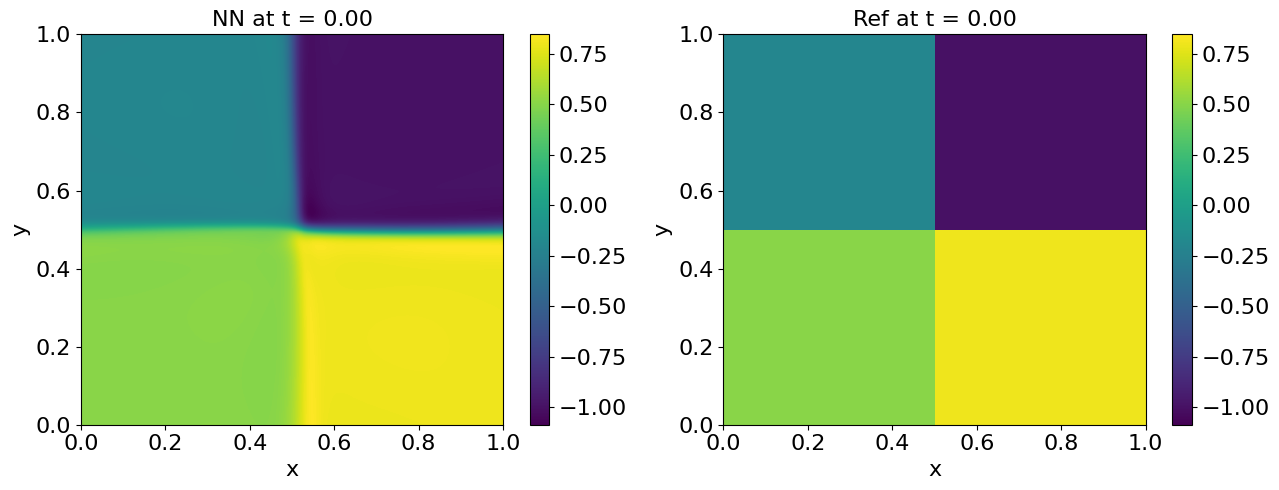

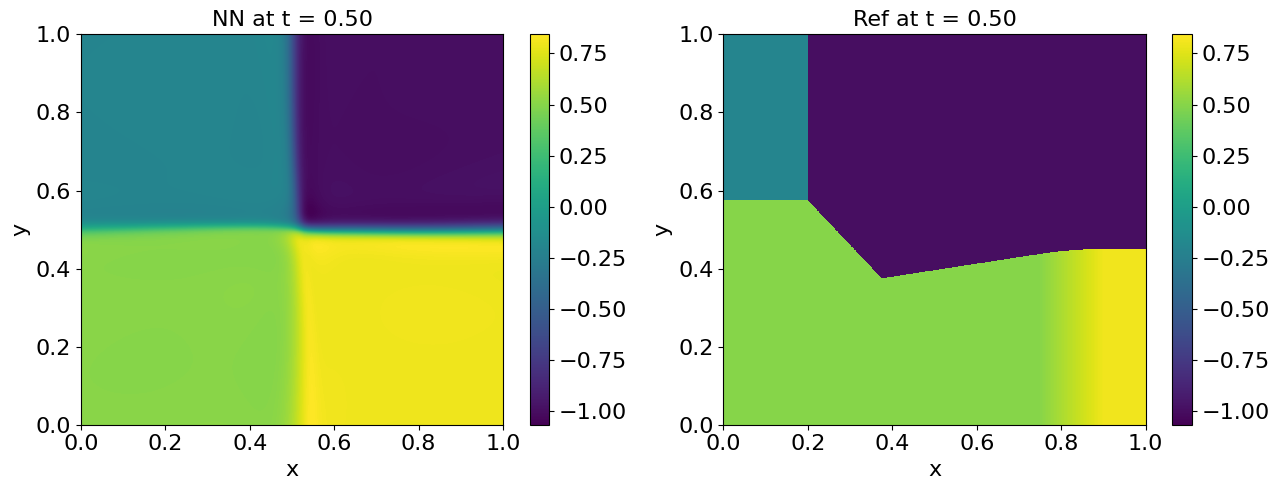

Grade 0, Iter 100, loss_eqn: 0.255493, loss_eqn_from_kh: 0.255383, loss_l1: 0.288122, loss_ibc: 0.083598
Grade 0, Iter 200, loss_eqn: 0.262559, loss_eqn_from_kh: 0.263463, loss_l1: 0.297694, loss_ibc: 0.041945
Grade 0, Iter 300, loss_eqn: 0.205661, loss_eqn_from_kh: 0.206067, loss_l1: 0.267033, loss_ibc: 0.028298
Grade 0, Iter 400, loss_eqn: 0.166500, loss_eqn_from_kh: 0.166038, loss_l1: 0.257016, loss_ibc: 0.020873
Grade 0, Iter 500, loss_eqn: 0.139790, loss_eqn_from_kh: 0.140805, loss_l1: 0.261731, loss_ibc: 0.015093
Grade 0, Iter 600, loss_eqn: 0.117479, loss_eqn_from_kh: 0.117589, loss_l1: 0.258729, loss_ibc: 0.011497
Grade 0, Iter 700, loss_eqn: 0.106591, loss_eqn_from_kh: 0.100861, loss_l1: 0.265197, loss_ibc: 0.009345
Grade 0, Iter 800, loss_eqn: 0.097087, loss_eqn_from_kh: 0.097146, loss_l1: 0.266526, loss_ibc: 0.008113
Grade 0, Iter 900, loss_eqn: 0.099294, loss_eqn_from_kh: 0.096219, loss_l1: 0.263510, loss_ibc: 0.007422
Grade 0, Iter 1000, loss_eqn: 0.081679, loss_eqn_from_k

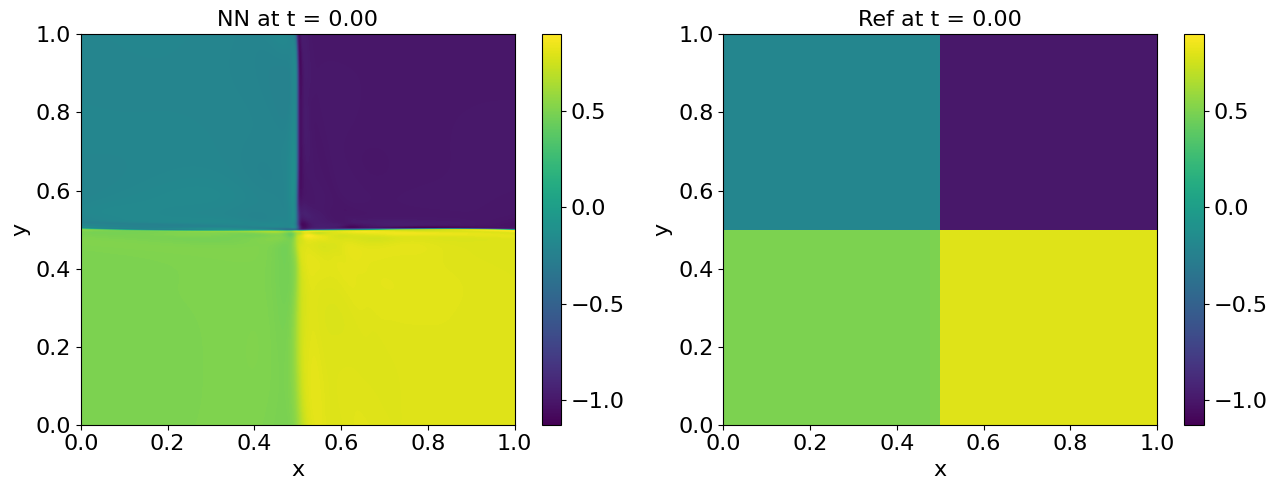

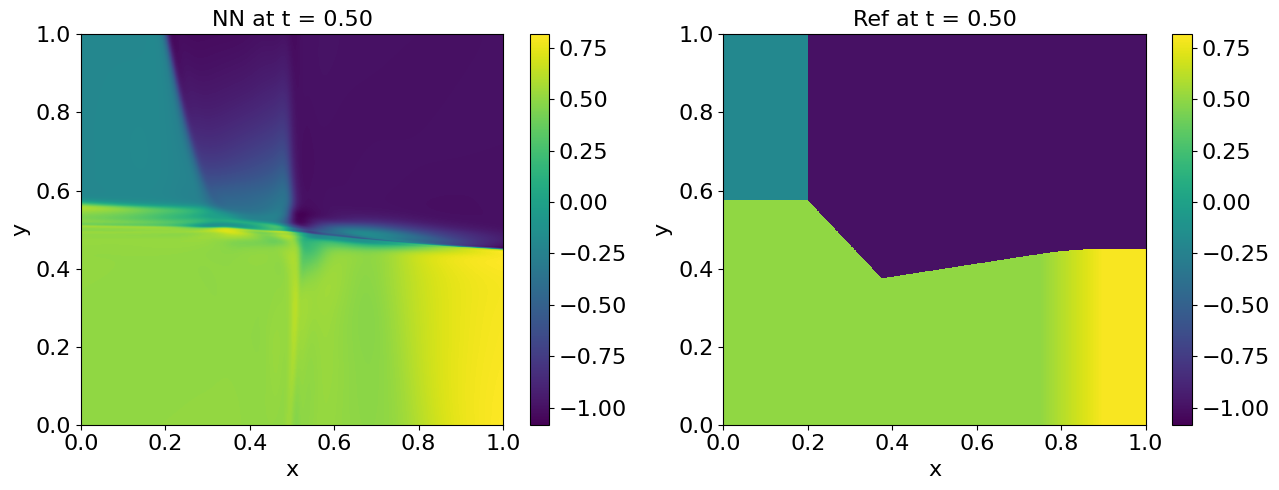

Grade 0, Iter 2100, loss_eqn: 0.044090, loss_eqn_from_kh: 0.041253, loss_l1: 0.199276, loss_ibc: 0.003103
Grade 0, Iter 2200, loss_eqn: 0.042741, loss_eqn_from_kh: 0.039531, loss_l1: 0.201467, loss_ibc: 0.002988
Grade 0, Iter 2300, loss_eqn: 0.040179, loss_eqn_from_kh: 0.042205, loss_l1: 0.200591, loss_ibc: 0.002877
Grade 0, Iter 2400, loss_eqn: 0.040530, loss_eqn_from_kh: 0.037271, loss_l1: 0.195916, loss_ibc: 0.002846
Grade 0, Iter 2500, loss_eqn: 0.048913, loss_eqn_from_kh: 0.038770, loss_l1: 0.187969, loss_ibc: 0.002938
Grade 0, Iter 2600, loss_eqn: 0.036721, loss_eqn_from_kh: 0.038539, loss_l1: 0.186112, loss_ibc: 0.002646
Grade 0, Iter 2700, loss_eqn: 0.034481, loss_eqn_from_kh: 0.032312, loss_l1: 0.177977, loss_ibc: 0.002521
Grade 0, Iter 2800, loss_eqn: 0.033823, loss_eqn_from_kh: 0.031694, loss_l1: 0.175961, loss_ibc: 0.002442
Grade 0, Iter 2900, loss_eqn: 0.035482, loss_eqn_from_kh: 0.032321, loss_l1: 0.176079, loss_ibc: 0.002454
Grade 0, Iter 3000, loss_eqn: 0.032187, loss_e

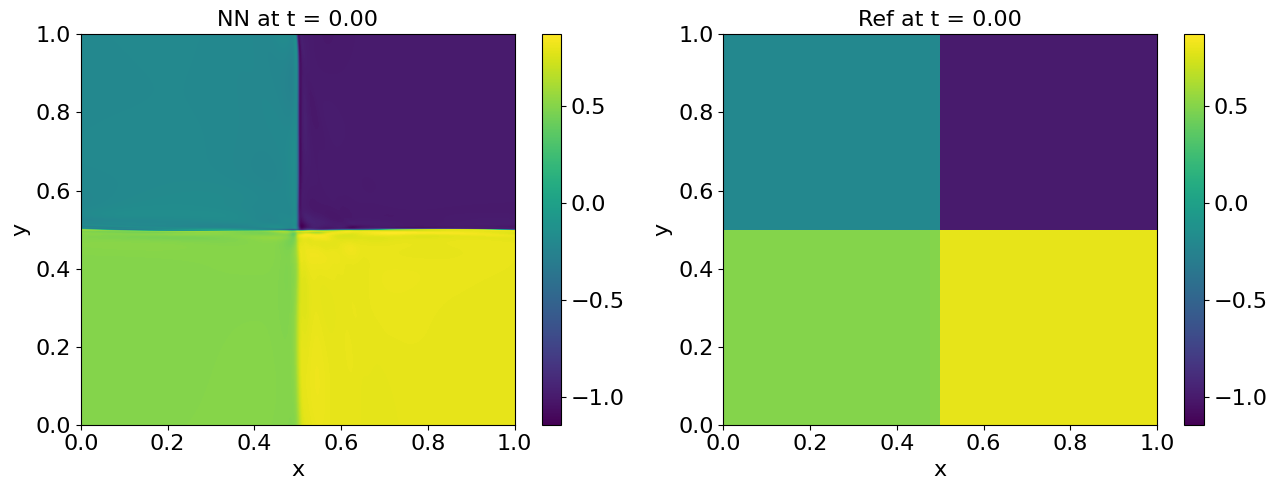

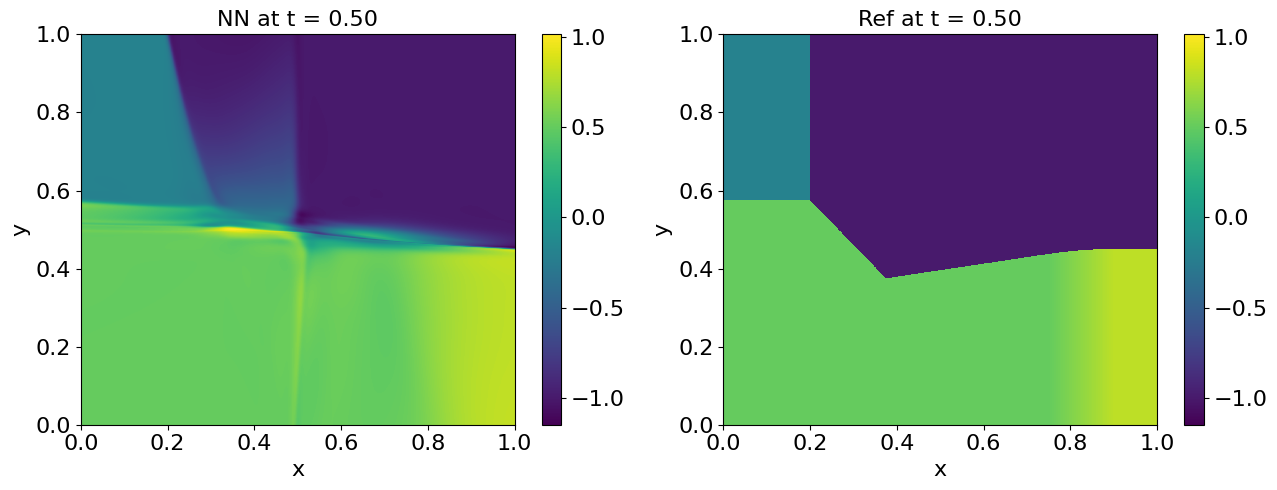

Grade 0, Iter 4100, loss_eqn: 0.025599, loss_eqn_from_kh: 0.025480, loss_l1: 0.158671, loss_ibc: 0.001819
Grade 0, Iter 4200, loss_eqn: 0.026262, loss_eqn_from_kh: 0.027481, loss_l1: 0.159760, loss_ibc: 0.001787
Grade 0, Iter 4300, loss_eqn: 0.026767, loss_eqn_from_kh: 0.025405, loss_l1: 0.159855, loss_ibc: 0.001737
Grade 0, Iter 4400, loss_eqn: 0.026448, loss_eqn_from_kh: 0.027482, loss_l1: 0.157738, loss_ibc: 0.001755
Grade 0, Iter 4500, loss_eqn: 0.027669, loss_eqn_from_kh: 0.026022, loss_l1: 0.158836, loss_ibc: 0.001681
Grade 0, Iter 4600, loss_eqn: 0.025121, loss_eqn_from_kh: 0.025589, loss_l1: 0.157793, loss_ibc: 0.001700
Grade 0, Iter 4700, loss_eqn: 0.025008, loss_eqn_from_kh: 0.024910, loss_l1: 0.155504, loss_ibc: 0.001612
Grade 0, Iter 4800, loss_eqn: 0.029484, loss_eqn_from_kh: 0.027827, loss_l1: 0.157133, loss_ibc: 0.001653
Grade 0, Iter 4900, loss_eqn: 0.027349, loss_eqn_from_kh: 0.029210, loss_l1: 0.156167, loss_ibc: 0.001678
Grade 0, Iter 5000, loss_eqn: 0.023781, loss_e

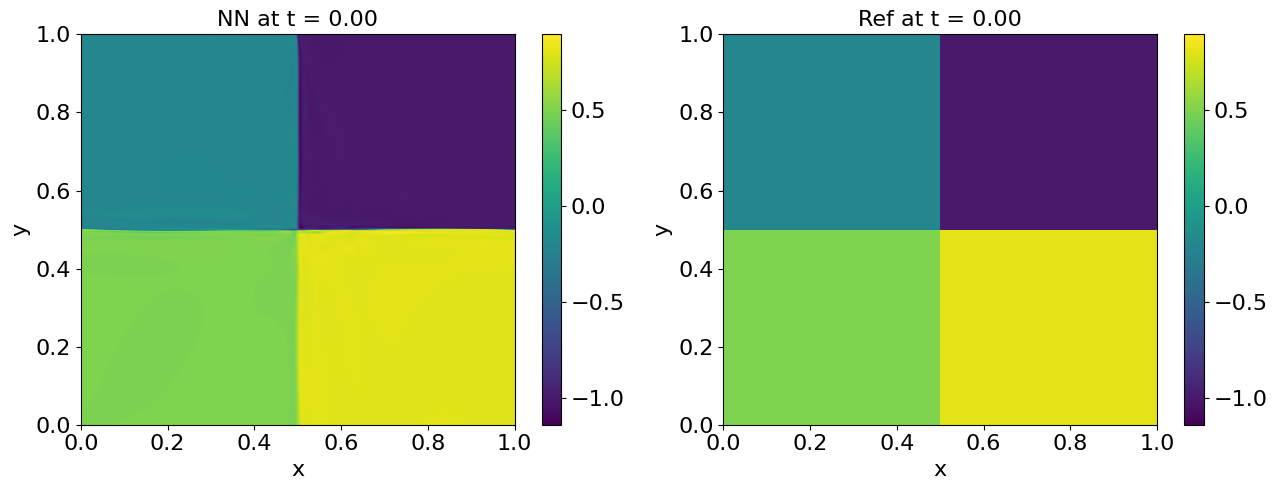

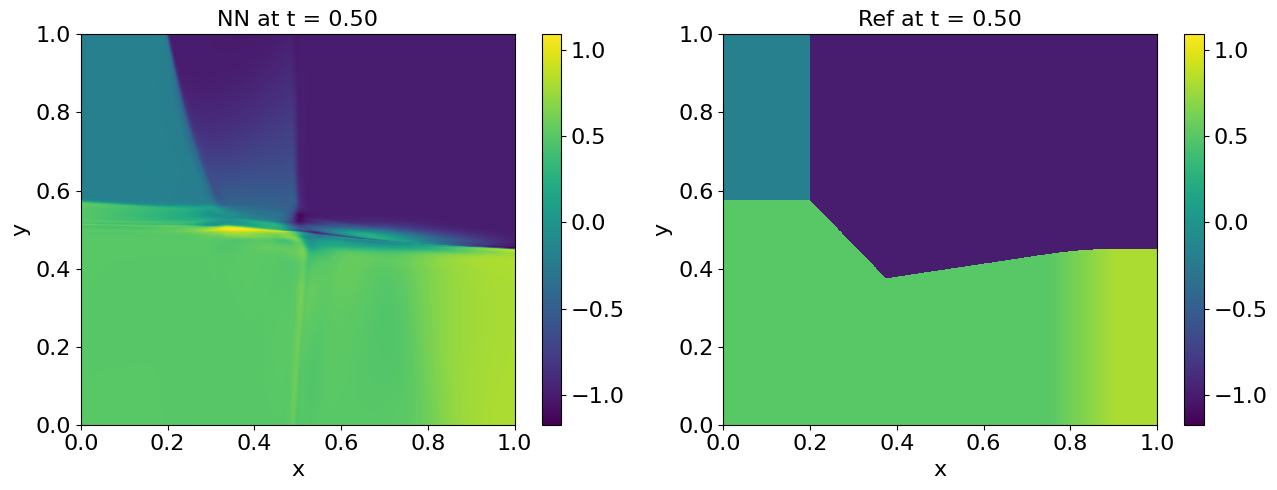

Grade 0, Iter 6100, loss_eqn: 0.021238, loss_eqn_from_kh: 0.022360, loss_l1: 0.147718, loss_ibc: 0.001296
Grade 0, Iter 6200, loss_eqn: 0.023844, loss_eqn_from_kh: 0.022769, loss_l1: 0.147364, loss_ibc: 0.001299
Grade 0, Iter 6300, loss_eqn: 0.021352, loss_eqn_from_kh: 0.021410, loss_l1: 0.144740, loss_ibc: 0.001290
Grade 0, Iter 6400, loss_eqn: 0.021357, loss_eqn_from_kh: 0.020726, loss_l1: 0.143901, loss_ibc: 0.001198
Grade 0, Iter 6500, loss_eqn: 0.031505, loss_eqn_from_kh: 0.033166, loss_l1: 0.154326, loss_ibc: 0.001631
Grade 0, Iter 6600, loss_eqn: 0.020873, loss_eqn_from_kh: 0.021322, loss_l1: 0.145027, loss_ibc: 0.001187
Grade 0, Iter 6700, loss_eqn: 0.019742, loss_eqn_from_kh: 0.020748, loss_l1: 0.140721, loss_ibc: 0.001148
Grade 0, Iter 6800, loss_eqn: 0.020595, loss_eqn_from_kh: 0.021058, loss_l1: 0.140596, loss_ibc: 0.001142
Grade 0, Iter 6900, loss_eqn: 0.019700, loss_eqn_from_kh: 0.019570, loss_l1: 0.140402, loss_ibc: 0.001139
Grade 0, Iter 7000, loss_eqn: 0.020278, loss_e

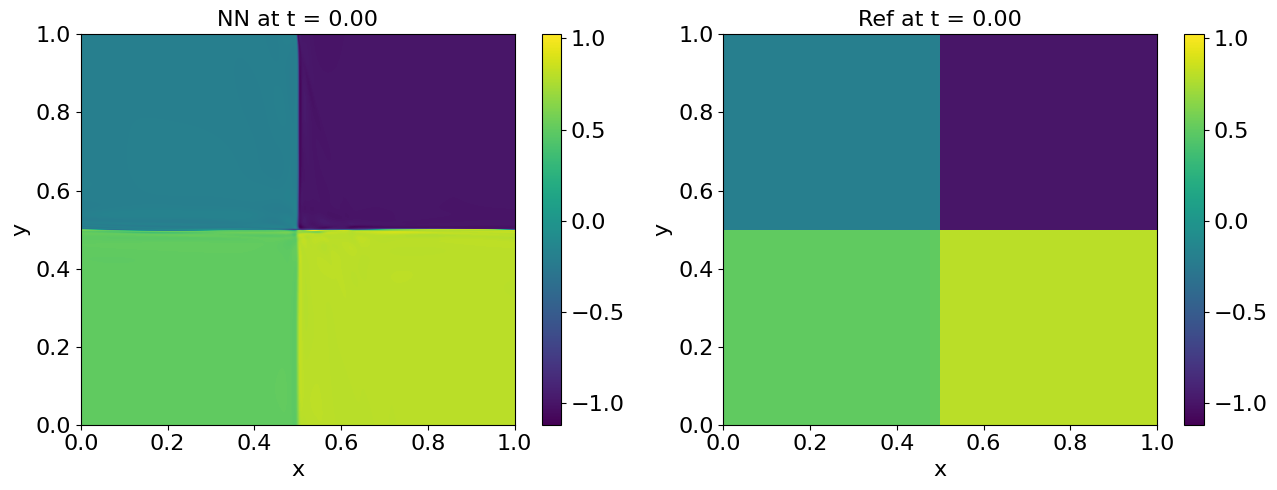

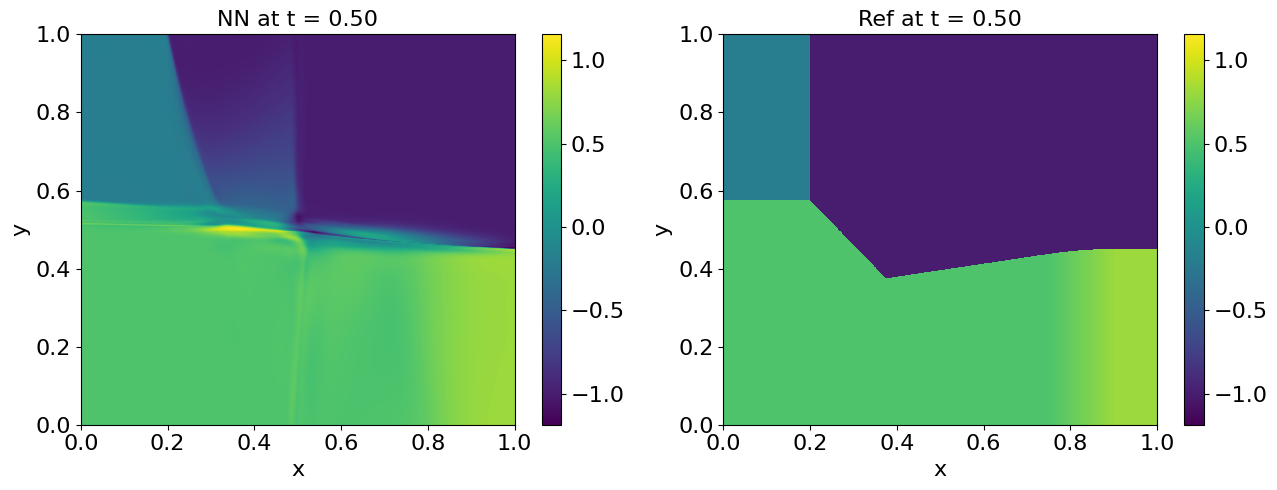

Grade 0, Iter 8100, loss_eqn: 0.020481, loss_eqn_from_kh: 0.020239, loss_l1: 0.134465, loss_ibc: 0.001026
Grade 0, Iter 8200, loss_eqn: 0.017697, loss_eqn_from_kh: 0.019296, loss_l1: 0.133366, loss_ibc: 0.000966
Grade 0, Iter 8300, loss_eqn: 0.018417, loss_eqn_from_kh: 0.018436, loss_l1: 0.131940, loss_ibc: 0.000964
Grade 0, Iter 8400, loss_eqn: 0.019557, loss_eqn_from_kh: 0.019421, loss_l1: 0.132118, loss_ibc: 0.000928
Grade 0, Iter 8500, loss_eqn: 0.018526, loss_eqn_from_kh: 0.017834, loss_l1: 0.131568, loss_ibc: 0.000967
Grade 0, Iter 8600, loss_eqn: 0.018982, loss_eqn_from_kh: 0.019005, loss_l1: 0.132170, loss_ibc: 0.000926
Grade 0, Iter 8700, loss_eqn: 0.017951, loss_eqn_from_kh: 0.017953, loss_l1: 0.132213, loss_ibc: 0.000890
Grade 0, Iter 8800, loss_eqn: 0.019007, loss_eqn_from_kh: 0.018121, loss_l1: 0.130235, loss_ibc: 0.000929
Grade 0, Iter 8900, loss_eqn: 0.018830, loss_eqn_from_kh: 0.019176, loss_l1: 0.131196, loss_ibc: 0.000892
Grade 0, Iter 9000, loss_eqn: 0.017504, loss_e

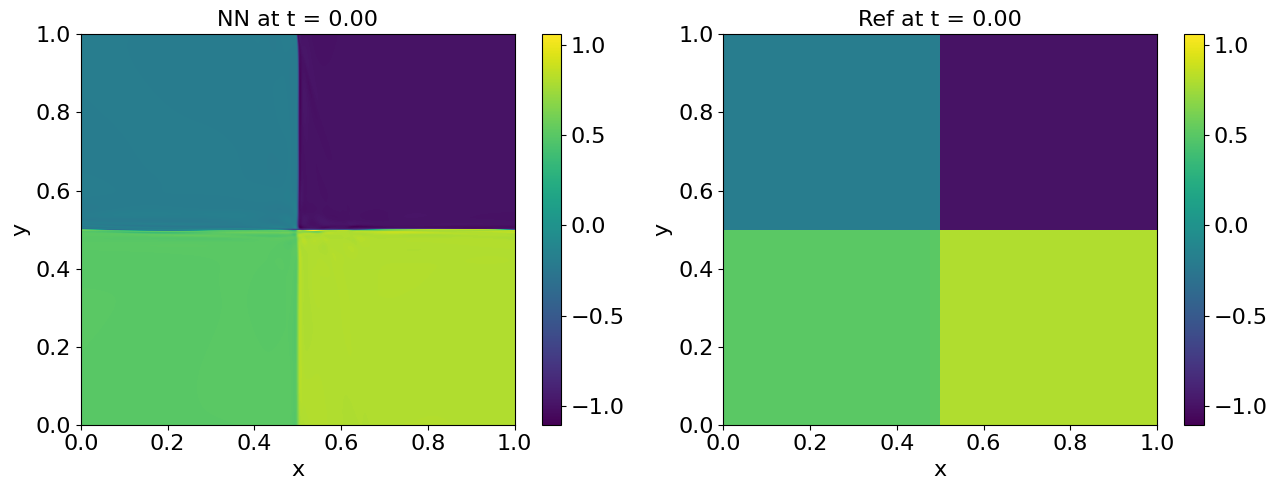

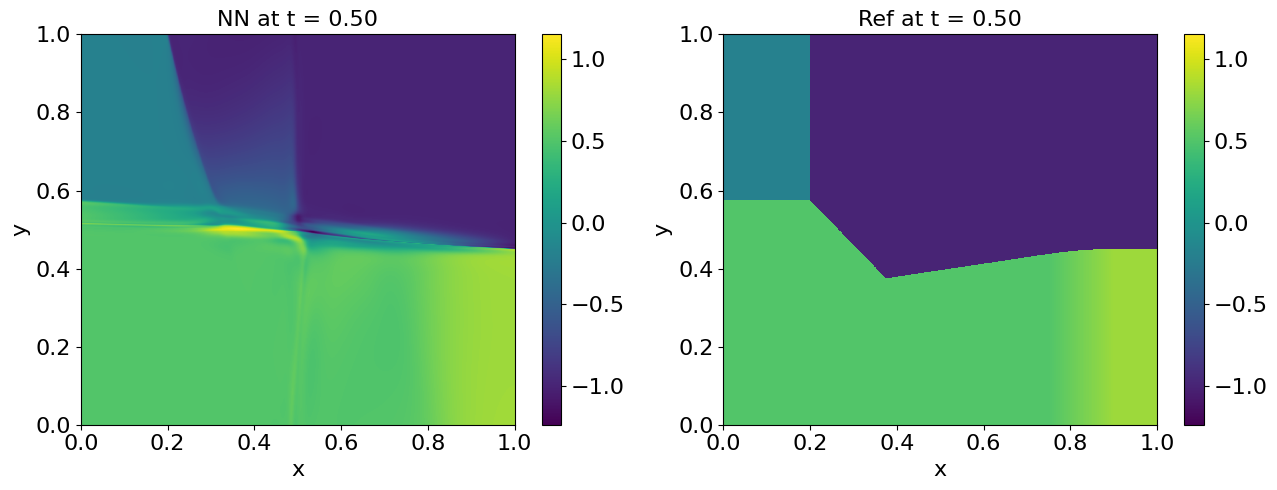

Grade 0, Iter 10100, loss_eqn: 0.015352, loss_eqn_from_kh: 0.016343, loss_l1: 0.129272, loss_ibc: 0.000791
Grade 0, Iter 10200, loss_eqn: 0.017256, loss_eqn_from_kh: 0.016817, loss_l1: 0.127201, loss_ibc: 0.000797


In [ ]:
optprob.train_seq()

In [5]:
optprob.pwp.quad_weights

Array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [12]:
import numpy as np

def u_ref(t, x, y):
    """
    Reference solution u(t, x, y).
    Returns 0 if y > 0.5 + 0.5*t, else 1.
    """
    return np.where(y > 0.5 + 0.5 * t, 0, 1)

def u0(x, y):
    """
    Initial condition u0(x, y) = u(0, x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder, since independent of x

def u_right(t, y):
    """
    Boundary condition at x = x_max (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder

def u_bottom(t, x):
    """
    Boundary condition at y = y_min (independent of x, so same as u_ref with y=y_min).
    """
    return u_ref(t, x, np.zeros_like(x))  # y=0 as placeholder, but function needs y

def u_top(t, x):
    """
    Boundary condition at y = y_max (independent of x, so same as u_ref with y=y_max).
    """
    return u_ref(t, x, np.ones_like(x))  # y=0 as placeholder, adjust if y_max known

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

In [13]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1
N_t = 8
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(input_dim=3, total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[2e-4, 1e-3, 1e-3], grade_epochs=[101, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 9.413791
Grade 0, Iter 0, lambda_ic: 18.335306, lambda_bc: 18.339373, lambda_eqn: 1.145638
Grade 0, Iter 0, loss_eqn: 0.410825, loss_eqn_from_kh: 0.410592, loss_l1: 0.410592, loss_ibc: 3.018623


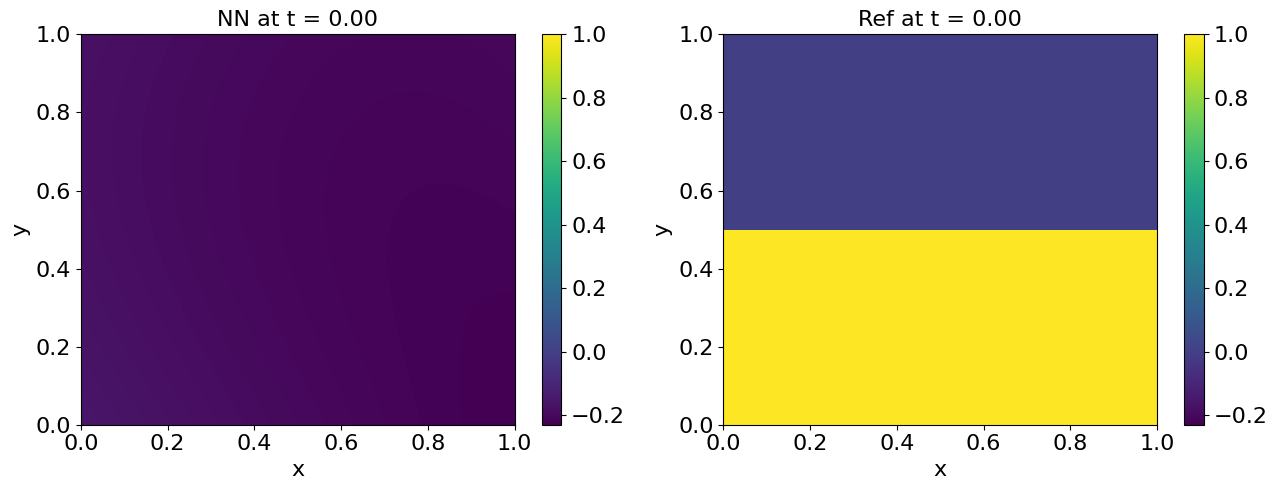

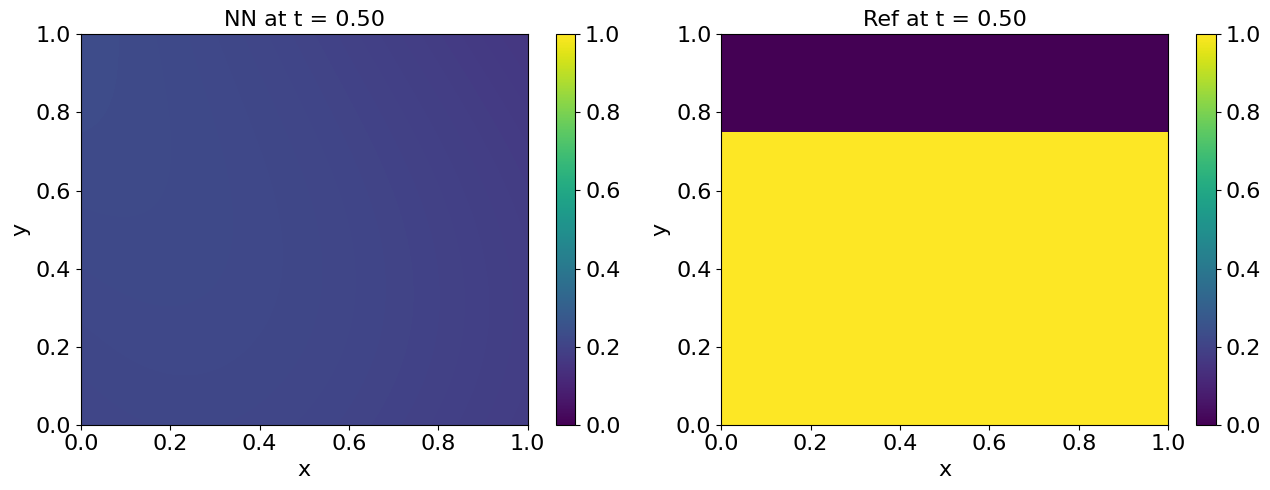

Grade 0, Iter 100, loss_eqn: 0.234396, loss_eqn_from_kh: 0.234049, loss_l1: 0.234049, loss_ibc: 0.275619
Train time for stage1: 92.617730 seconds

Plotting after training segment [0.0000, 0.5000]


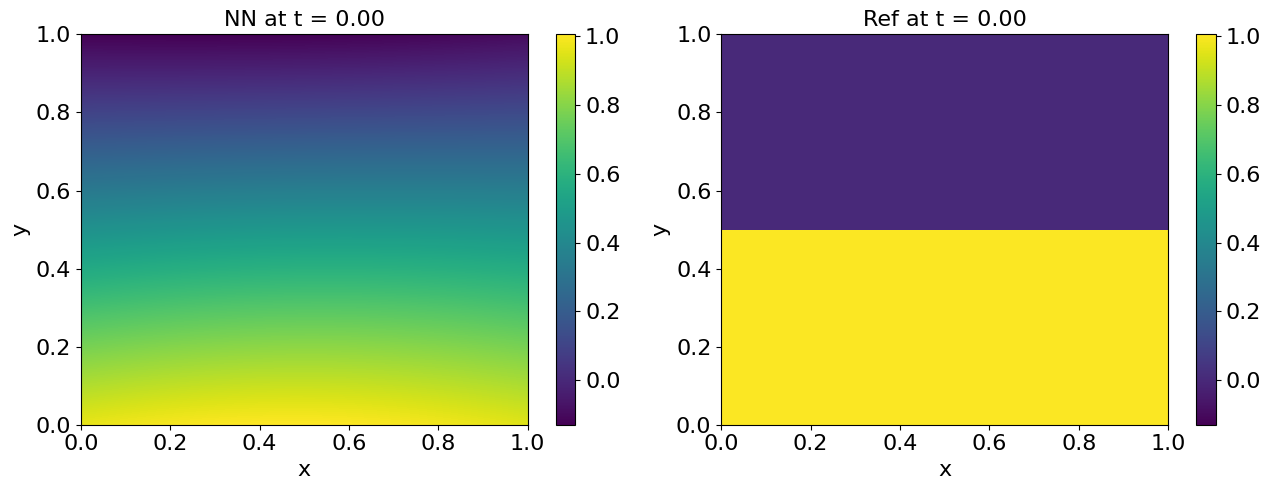

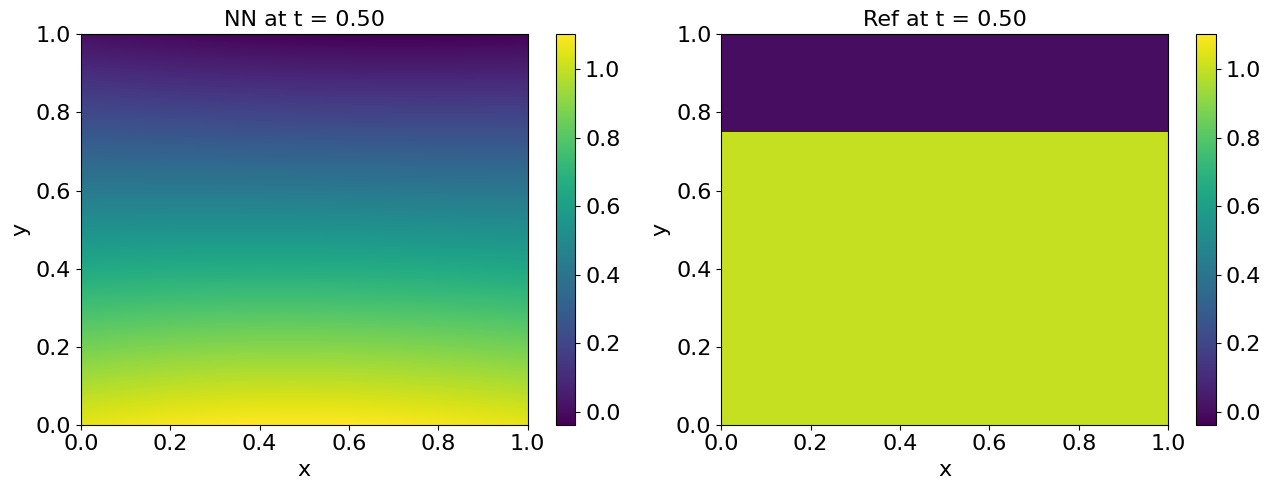

In [14]:
optprob.train_seq()

In [7]:
self = optprob.segments[0]
self.input_dim
self.u_ref(0.5, 1, 0.5)

IndexError: list index out of range

In [ ]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [8]:
self = optprob
params = optprob.model.mlps[0].params
self.gen_funcs(0)
self.pwp.coeffs, self.key, loss_eqn_from_kh, loss_l1, loss_each_elem = self.maximize_kh_step(params, self.key)

In [9]:
Nt = self.pwp.N_elements
quad_points = self.pwp.quad_points_parti
u_values_all = self.u_eval(params, quad_points)
quad_weights = self.pwp.quad_weights_parti
avg_vals = jnp.einsum('ij,ij->i', u_values_all, quad_weights)/self.elem_meas
init_coeffs_all = jnp.hstack([avg_vals[..., None] , jnp.zeros((Nt, self.p_dof - 1))])
perturbations_all = self.sigma * jax.random.uniform(self.key, (self.N_perturb, self.p_dof), minval=-1, maxval=1)
perturbed_coeffs_all = init_coeffs_all[:, None, :] + perturbations_all[None, :, :]

In [35]:
parti_idx = 0
quad_points = self.pwp.quad_points_parti[parti_idx]
quad_weights = self.pwp.quad_weights_parti[parti_idx]
u_quad = self.u_eval(params, quad_points)
grad_u_tx = self.grad_u(params, quad_points)

In [36]:
quad_points.shape

(64, 3)

In [11]:
u_t, u_x, u_y = grad_u_tx[:, 0], grad_u_tx[:, 1], grad_u_tx[:, 2]
residual = self.res(u_quad, u_t, u_x, u_y).flatten()
p_coeffs_all = perturbed_coeffs_all[parti_idx]
k_h_quad_all = (p_coeffs_all[:, 0][:, None] + 
                p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
                p_coeffs_all[:, 2][:, None] * quad_points[:, 1] + 
                p_coeffs_all[:, 3][:, None] * quad_points[:, 2]
               )
k_h_quad_all1 = jnp.einsum('ik,kj->ij', p_coeffs_all[:, 1:], quad_points.T) + p_coeffs_all[:, 0][:, None]

In [12]:
jnp.min(k_h_quad_all1-k_h_quad_all)

Array(-9.536743e-07, dtype=float32)

In [33]:
quad_points = self.pwp.quad_points
p_coeffs_quad = self.pwp.coeffs[self.pwp.element_indices]
k_h_quad = p_coeffs_quad[:, 0] + jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1)
k_h_quad1 = jnp.einsum('ij, ij->i', p_coeffs_quad[:, 1:], quad_points) + p_coeffs_quad[:, 0]

In [34]:
jnp.max(jnp.abs(k_h_quad-k_h_quad1))

Array(0., dtype=float32)

In [ ]:
jnp.max(k_h_quad-k_h_quad1)

In [28]:
jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1).shape

(41472,)

In [37]:
self.pwp.quad_points.shape

(41472, 3)

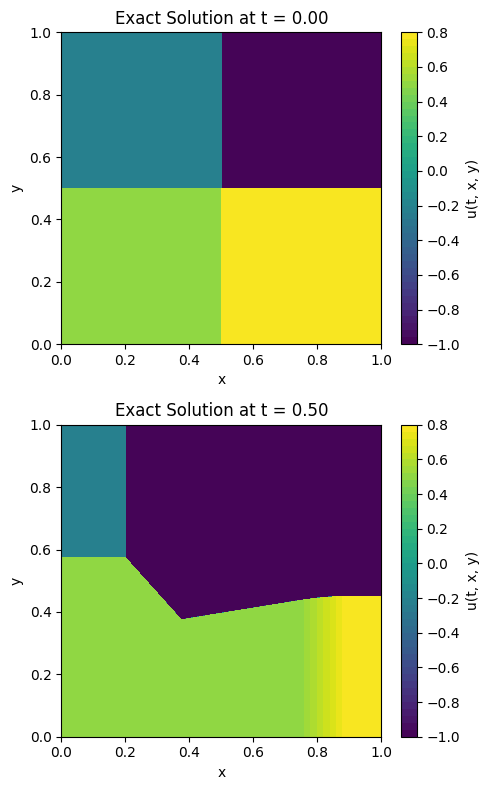

In [12]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [77]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0

tau = (t_max - t_min) / N_t
hx = (x_max - x_min) / N_x
hy = (y_max - y_min) / N_y
t_starts = jnp.linspace(t_min, t_max - tau, N_t)
x_starts = jnp.linspace(x_min, x_max - hx, N_x)
y_starts = jnp.linspace(y_min, y_max - hy, N_y)
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
# Define the 8 vertices for each hexahedron using binary offsets
offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
deltas = jnp.array([tau, hx, hy])
offsets = offsets_bin * deltas  # (8,3)
lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)

In [83]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts)
xl.shape

(5, 10, 2)

In [82]:
tl

Array([[[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9

In [69]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)

# Tensor product for 3D
t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)

In [79]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
tl.shape

(10, 5, 2)

In [72]:
t_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [73]:
x_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967]],

       [[ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ]],

       [[ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [74]:
y_nodes

Array([[[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]]], dtype=float32)